# wellmodel - end-to-end demo

This notebook runs the full workflow on a **synthetic well with a known answer**, so every step can be checked:

1. Build the well (PVT, deviation survey, tubing)
2. **Test data QC** - catch bad tests before they reach the match
3. **Correlation selection** - rank VLP correlations by leave-one-out prediction error
4. **Automated multi-test matching** - fit gravity/friction multipliers and PI to all good tests at once, with uncertainty
5. **Probabilistic nodal run** - P90/P50/P10 rate with input *and* model-parameter uncertainty
6. **Transient behaviour** - build-up interpretation (independent PI check) and a depletion forecast that flags when natural flow ends

The truth well uses the modified Hagedorn & Brown correlation with gravity multiplier 1.04, friction multiplier 1.15 and PI 2.61 STB/d/psi. Four problems are planted in the tests.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

import wellmodel as wm
from wellmodel import plotting as wplt
from wellmodel.synthetic import (demo_well, make_tests, make_buildup, demo_reservoir,
                                 demo_stoiip, TRUTH)

## 1. The well
A 30°-deviated producer, 4½" tubing (3.958" ID), gauge at 10,000 ft MD, perforations at 10,400 ft MD. We start from an *unmatched* model: Beggs & Brill, multipliers 1, PI unknown.

In [2]:
base = demo_well(truth=False)
print("PVT:", base.pvt.summary())
print("Wellbore:", base.wellbore.summary())

PVT: {'API': 32.0, 'gas_sg': 0.75, 'Rsb': 600.0, 'T_res': 210.0, 'Pb': 2863.4, 'Bob': 1.353, 'mu_ob': 0.556, 'rho_ob': 44.46}
Wellbore: {'perf_MD': 10400.0, 'perf_TVD': 9425.5, 'gauge_MD': 10000.0, 'gauge_TVD': 9079.1, 'tubing_ID_in': [3.958], 'max_inclination_deg': 30.0, 'grid_nodes': 39}


## 2. Well tests and QC
Fourteen tests over three years of depletion and water-cut rise. Planted problems: **T04** gauge +200 psi, **T08** rate +30 %, **T11** GOR −40 % (meter fault), **T06** only 3 hours long.

In [3]:
tests, truth = make_tests()
tests

,test_id,date,liquid_rate,water_cut,gor,whp,gauge_pressure,reservoir_pressure,duration_hr,rate_cv
0,T01,2023-01-15,"5,231.500",0.040,599.400,196.300,"2,005.600","4,209.700",18.300,0.015
1,T02,2023-04-09,"4,431.700",0.054,601.400,340.200,"2,324.700","4,120.300",17.100,0.049
2,T03,2023-07-02,"4,659.800",0.051,581.600,264.100,"2,149.800","4,093.400",14.000,0.036
3,T04,2023-09-24,"3,704.700",0.075,594.300,395.400,"2,686.600","4,049.000",14.600,0.027
4,T05,2023-12-18,"4,484.700",0.082,588.300,232.600,"2,098.600","4,019.500",11.800,0.031
5,T06,2024-03-11,"3,909.300",0.108,590.300,300.400,"2,283.700","3,961.100",3.000,0.045
6,T07,2024-06-03,"4,333.500",0.127,612.700,198.100,"2,061.200","3,896.000",22.000,0.024
7,T08,2024-08-27,"4,430.500",0.164,590.300,346.000,"2,436.800","3,845.500",15.500,0.034
8,T09,2024-11-19,"3,590.300",0.182,599.600,262.300,"2,262.900","3,797.500",16.800,0.037
9,T10,2025-02-11,"2,444.800",0.221,610.600,396.400,"2,685.300","3,774.200",13.200,0.024


In [4]:
qc = wm.qc_tests(base, tests)
print(qc.counts())
qc.table[["test_id", "status", "weight", "pi_implied", "pi_z", "reasons"]]

{'pass': 10, 'fail': 3, 'warn': 1}


,test_id,status,weight,pi_implied,pi_z,reasons
0,T01,pass,1.000,2.601,-0.551,
1,T02,pass,1.000,2.671,0.692,
2,T03,pass,1.000,2.619,-0.071,
3,T04,fail,0.000,2.959,5.600,implied PI 2.96 is +5.6 robust sigma from tren...
4,T05,pass,1.000,2.567,-0.730,
5,T06,warn,0.500,2.549,-0.939,test only 3.0 h long (< 6.0 h)
6,T07,pass,1.000,2.621,0.328,
7,T08,fail,0.000,3.464,14.262,implied PI 3.46 is +14.3 robust sigma from tre...
8,T09,pass,1.000,2.590,0.017,
9,T10,pass,1.000,2.515,-1.135,


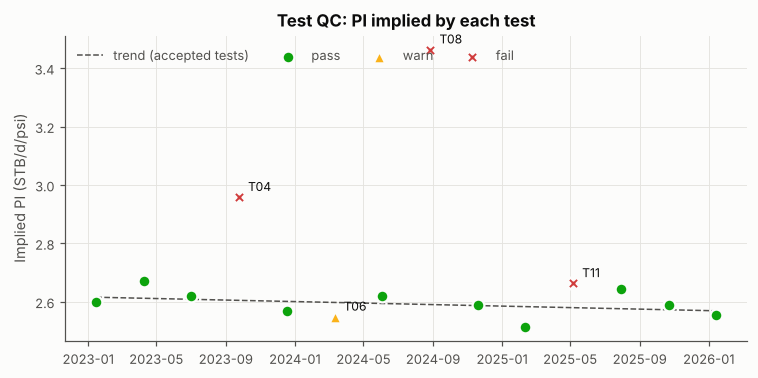

In [5]:
wplt.plot_qc(qc);

Every planted problem is caught, each with a reason an engineer can act on. T04 and T08 are not visible in any single number - they are found because the PI each test implies falls far off the robust trend of the other tests. T11 fails two independent checks (GOR below Rsb while undersaturated, and a gauge pressure no reasonable tubing model can reach). T06 is kept at half weight.

## 3. Correlation selection
Each correlation is matched to the QC-weighted tests, then scored by **leave-one-out cross-validation**: refit without each test and predict it. A correlation that needs out-of-range multipliers to fit ranks behind every correlation that doesn't.

In [6]:
sel = wm.compare_correlations(base, tests, weights=qc.weights)
sel.table[["rank", "label", "raw_gauge_bias", "matched_gauge_rmse", "loocv_gauge_rmse",
           "loocv_rate_mape", "gravity_mult", "friction_mult", "in_range"]]

,rank,label,raw_gauge_bias,matched_gauge_rmse,loocv_gauge_rmse,loocv_rate_mape,gravity_mult,friction_mult,in_range
0,1,Hagedorn & Brown (mod.),-142.702,23.622,28.397,2.136,1.045,1.095,True
1,2,Beggs & Brill,162.363,22.250,26.232,2.206,0.962,0.705,False
2,3,No-slip homogeneous,-210.100,42.794,47.593,2.637,1.044,1.463,False


Recommended: Hagedorn & Brown (mod.) - lowest leave-one-out gauge RMSE (28 psi) with gravity multiplier 1.045 and friction multiplier 1.095.
Its out-of-the-box bias is -143 psi at the gauge, and the match stays within the acceptable multiplier ranges.
Beggs & Brill: rejected - needs out-of-range multipliers, leave-one-out gauge RMSE 26 psi.
No-slip homogeneous: rejected - needs out-of-range multipliers, leave-one-out gauge RMSE 48 psi.


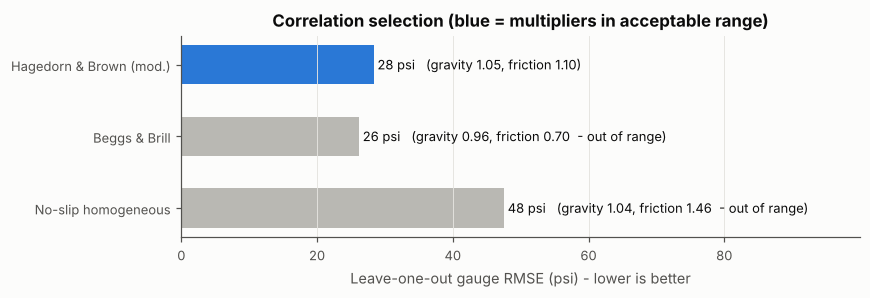

In [7]:
print(sel.rationale)
wplt.plot_selection(sel);

The truth correlation is recommended. Note the honest detail in the table: Beggs & Brill reaches a similar statistical fit, but only by cutting friction to ~0.70 - outside the acceptable band. With noisy field data statistics alone often cannot separate correlations; the multiplier rule is what makes the choice defensible, and the tool shows both so the engineer can judge.

## 4. Multi-test match

In [8]:
match = sel.matches[sel.recommended]
model = match.model(base)
print("Flags:", match.flags or "none")
out = match.summary()
out["truth"] = [TRUTH["gravity_mult"], TRUTH["friction_mult"], truth["pi"]]
out

Flags: none


,parameter,value,std_error,acceptable_range,within_range,truth
0,gravity_mult,1.045,0.004,0.9-1.1,yes,1.040
1,friction_mult,1.095,0.095,0.75-1.25,yes,1.150
2,pi,2.595,0.025,,,2.613


In [9]:
print("Parameter correlation matrix:")
match.correlation_matrix.round(2)

Parameter correlation matrix:


,gravity_mult,friction_mult,pi
gravity_mult,1.000,-0.740,0.410
friction_mult,-0.740,1.000,-0.030
pi,0.410,-0.030,1.000


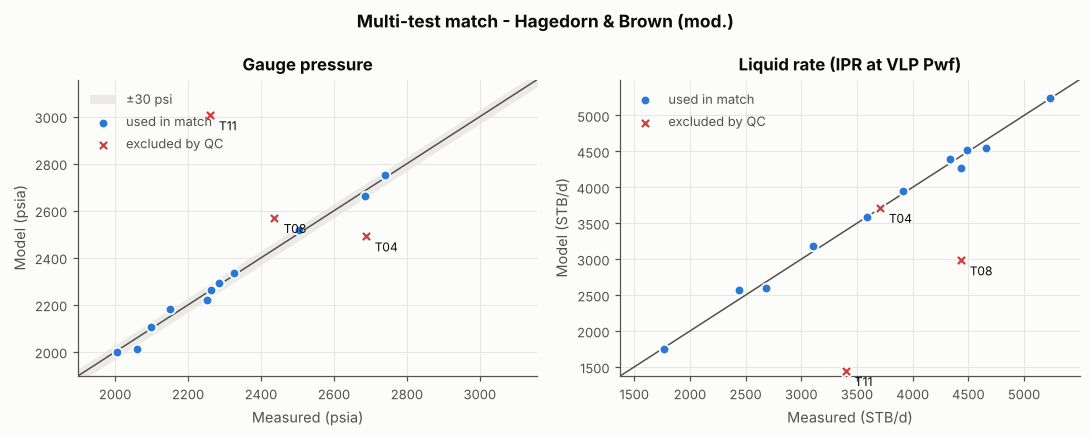

In [10]:
wplt.plot_match(match);

In [11]:
match.residuals[["test_id", "weight", "gauge_meas", "gauge_calc", "gauge_error",
                  "rate_meas", "rate_nodal", "nodal_error_pct"]].round(1)

,test_id,weight,gauge_meas,gauge_calc,gauge_error,rate_meas,rate_nodal,nodal_error_pct
0,T01,1.000,"2,005.600","1,997.900",-7.700,"5,231.500","5,236.500",0.100
1,T02,1.000,"2,324.700","2,336.900",12.200,"4,431.700","4,296.600",-3.000
2,T03,1.000,"2,149.800","2,182.700",32.900,"4,659.800","4,562.200",-2.100
3,T04,0.000,"2,686.600","2,492.200",-194.400,"3,704.700","3,716.300",0.300
4,T05,1.000,"2,098.600","2,107.400",8.800,"4,484.700","4,507.500",0.500
5,T06,0.500,"2,283.700","2,294.200",10.500,"3,909.300","3,942.100",0.800
6,T07,1.000,"2,061.200","2,010.400",-50.800,"4,333.500","4,383.100",1.100
7,T08,0.000,"2,436.800","2,570.600",133.800,"4,430.500","3,202.100",-27.700
8,T09,1.000,"2,262.900","2,261.500",-1.400,"3,590.300","3,591.400",0.000
9,T10,1.000,"2,685.300","2,661.700",-23.600,"2,444.800","2,560.400",4.700


All three parameters are recovered within about one standard error of the truth, from noisy data, with the bad tests excluded automatically. The last table is the PROSPER-style check run for every test at once: given only the measured WHP, how well does the matched model predict the rate?

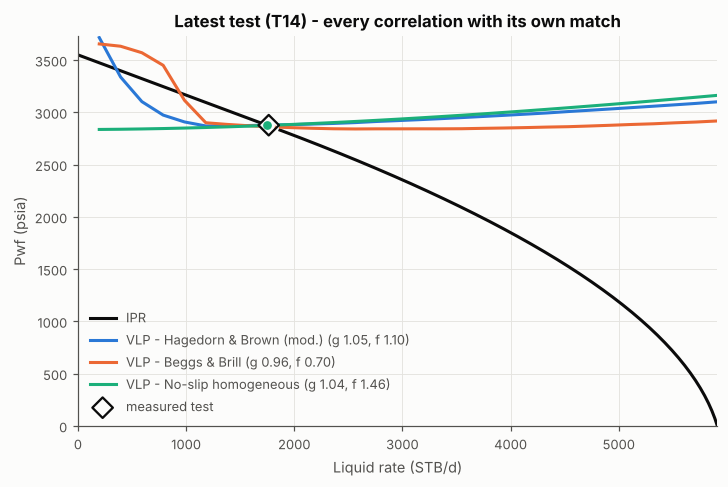

In [12]:
last = tests.iloc[-1]
each = [sel.matches[c].model(base) for c in sel.table["correlation"]]   # each with its OWN match
pwf_meas = model.pwf_vlp(last.liquid_rate, last.water_cut, last.gor, last.whp)[0]
wplt.plot_nodal(each, last.reservoir_pressure, last.whp, last.water_cut, last.gor,
                measured=(last.liquid_rate, pwf_meas),
                title=f"Latest test ({last.test_id}) - every correlation with its own match");

All three matched correlations pass close to the measured test, which is exactly why matching alone cannot pick a correlation. They diverge away from the matched conditions - at low rates and in the VLP minimum, which governs when the well stops flowing. That divergence is what the leave-one-out ranking and the multiplier rule protect against.

## 5. Probabilistic run: next quarter's rate
Inputs carry their own uncertainty, and the **match covariance** propagates the fitted gravity multiplier, friction multiplier and PI jointly (including their correlation), so model uncertainty is part of the answer rather than ignored.

In [13]:
inputs = {
    "reservoir_pressure": wm.Triangular(3400, 3480, 3560),
    "water_cut":          wm.Triangular(0.34, 0.37, 0.42),
    "gor":                wm.Normal(600, 20),
    "whp":                wm.Uniform(240, 300),
}
mc = wm.monte_carlo(model, inputs, n=2000, seed=1, match=match)
print(f"P(well flows naturally) = {mc.summary.attrs['prob_flowing']:.0%}, "
      f"P(unstable flow) = {mc.summary.attrs['prob_unstable']:.0%}")
mc.summary.round(0)

P(well flows naturally) = 100%, P(unstable flow) = 0%


,P90,P50,P10,mean
rate,"1,620.000","1,931.000","2,215.000","1,923.000"
oil_rate,990.000,"1,204.000","1,403.000","1,200.000"
pwf,"2,622.000","2,731.000","2,851.000","2,736.000"


,variable,spearman_rho
0,whp,-0.623
1,gor,0.509
2,water_cut,-0.447
3,reservoir_pressure,0.284
4,gravity_mult,-0.087
5,friction_mult,0.062
6,pi,0.028


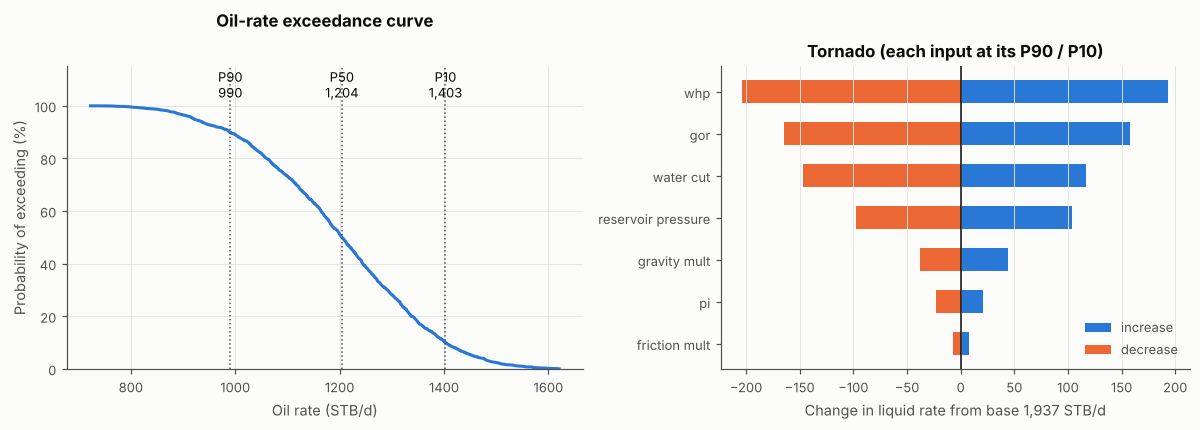

In [14]:
wplt.plot_monte_carlo(mc);
mc.sensitivity.round(3)

WHP and GOR dominate the spread here; the matched model parameters contribute little because the multi-test match pinned them down. That is itself useful: it says better separator and choke data would narrow the forecast more than more model tuning would.

## 6. Transient behaviour
### 6a. Build-up interpretation - an independent PI check

k = 50.01 ± 0.01 md, skin = 2.00 ± 0.00, C = 0.0300 bbl/psi, p* = 3559.9 psia, fit RMSE = 0.32 psi
PSS PI from build-up = 2.61  vs  PI from multi-test match = 2.60


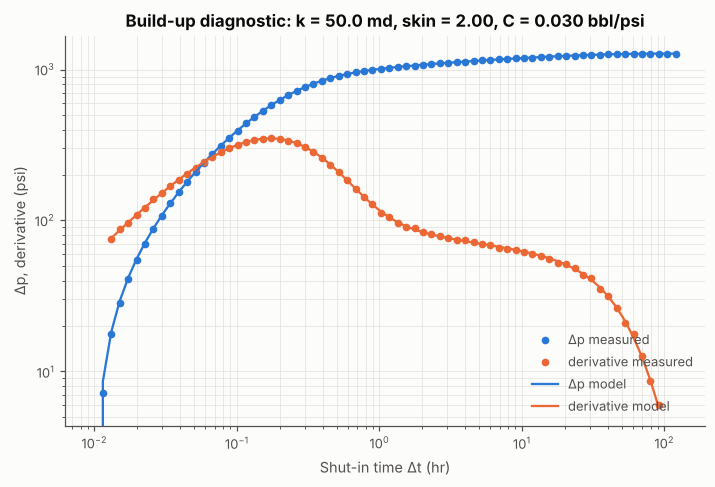

In [15]:
bu = make_buildup()
from dataclasses import replace
guess = replace(demo_reservoir(), k=10.0, skin=0.0, C=0.01)       # deliberately poor start
fit = wm.fit_buildup(bu.dt_hr, bu.pws, tp_hr=240, q=3500, guess=guess)
r = fit.reservoir
print(f"k = {r.k:.2f} ± {fit.std_errors['k']:.2f} md, skin = {r.skin:.2f} ± {fit.std_errors['skin']:.2f}, "
      f"C = {r.C:.4f} bbl/psi, p* = {fit.p_init:.1f} psia, fit RMSE = {fit.rmse:.2f} psi")
print(f"PSS PI from build-up = {fit.pi_pss:.2f}  vs  PI from multi-test match = {match.params['pi']:.2f}")
wplt.plot_buildup(bu.dt_hr.to_numpy(), bu.pws.to_numpy(), fit, 240, 3500);

The log-log plot shows the classic signature - unit-slope wellbore storage, the skin hump, then the flat radial-flow derivative - and the PI from the build-up agrees with the PI from production tests. Two independent data sources agreeing is the strongest validation a well model can have.

### 6b. Depletion forecast with flow-stop warning

In [16]:
fc_inputs = wm.DepletionInputs(
    stoiip=45e6, p_init=4200, aquifer_pi=6.0, whp=250, max_liquid_rate=5000,
    water_cut=wm.logistic_water_cut(wc0=0.04, wc_max=0.95, rf50=0.10, width=0.035),
)
fr = wm.forecast(model, fc_inputs, days=15 * 365, step_days=30, reservoir=demo_reservoir())
ev = {k: (None if v is None else round(float(v), 1)) for k, v in fr.events.items()}
ev

{'pss_reached_days': 3.7,
 'pr_below_pb_days': None,
 'unstable_from_days': None,
 'flow_stops_days': 4200.0,
 'np_at_flow_stop': 5915784.6}

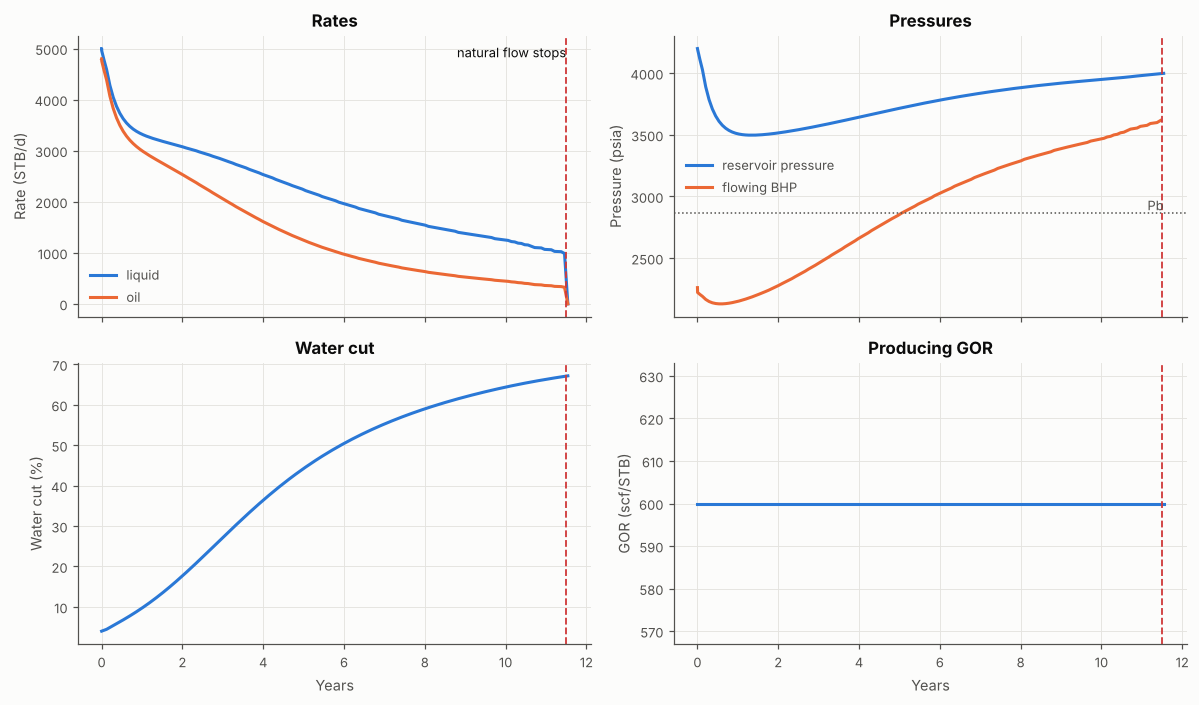

In [17]:
wplt.plot_forecast(fr, pb=model.pvt.pb);

In [18]:
yr = fr.table.copy(); yr["year"] = (yr.t_days // 365).astype(int)
yr.groupby("year").agg(reservoir_pressure=("reservoir_pressure", "last"), liquid_rate=("liquid_rate", "mean"),
                       oil_rate=("oil_rate", "mean"), water_cut=("water_cut", "last"),
                       gor=("gor", "last"), flowing=("flowing", "last")).round(2)

,reservoir_pressure,liquid_rate,oil_rate,water_cut,gor,flowing
year,,,,,,
0,"3,513.170","4,207.960","3,976.820",0.090,600.000,True
1,"3,512.460","3,194.720","2,770.180",0.170,600.000,True
2,"3,567.380","2,964.060","2,313.330",0.260,600.000,True
3,"3,642.100","2,683.420","1,833.560",0.360,600.000,True
4,"3,713.270","2,378.720","1,414.960",0.440,600.000,True
5,"3,778.840","2,094.050","1,100.900",0.500,600.000,True
6,"3,834.460","1,845.230",870.100,0.550,600.000,True
7,"3,879.910","1,636.220",702.440,0.590,600.000,True
8,"3,916.440","1,463.450",579.550,0.620,600.000,True


The forecast steps the matched well model through time: material balance updates reservoir pressure, gas comes out of solution below Pb, water cut rises, and at every step a full nodal solve decides whether the well can still lift its own fluids. The output a planner needs is the **date natural flow ends** - when artificial lift (gas lift or ESP) has to be in place.

### Limits to keep in mind
- Steady-state VLP at each time step; slugging and start-up dynamics need a full transient simulator (e.g. OLGA).
- Single-layer homogeneous reservoir; water cut and GOR follow trend functions you set, not relative permeability.
- Black-oil correlations are screening-grade; replace with lab PVT where available.
- Validated here against synthetic data only - real tests must be the next check.